# Representational geometry: predicted vs. learned

The project's claim: the geometry a network learns is **predictable in closed form** from the
structure of the task.

For sweeps, use the CLI instead, e.g. `python -m src.code.train -m runner=klinear setting=graph structure=ring,chain`.

In [1]:
import sys
import numpy as np
from pyprojroot import here
sys.path.append(str(here()))

from src.code.data import graph_conditional
from src.code.geometry import predicted_geometry
from src.code.eval import cka, rsa
from src.code.train import train_inline, graph_overrides
from src.code import plot_utils           # importing this applies the house plotting style

## 1. The predicted geometry (closed form)

Factor the ring's log-conditional — no training. The translation symmetry gives a degenerate
top Fourier pair, and the top-2 code lands on a circle.

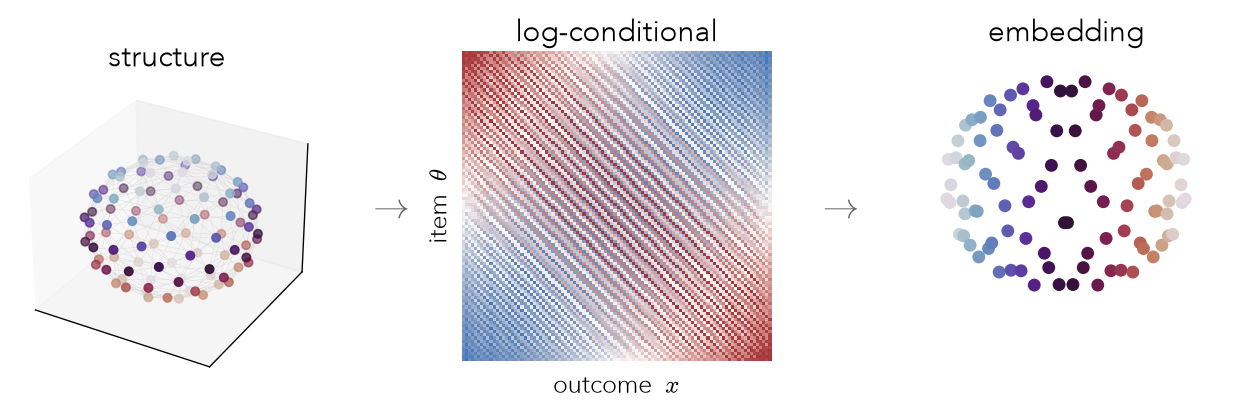

In [41]:
# pick a structure here — everything below follows from it
spec = {"structure": "sphere", "n": 100, "gamma": 0.8}
L = graph_conditional(spec)
E_pred = predicted_geometry(L)
plot_utils.plot_predicted_geometry(spec, L, E_pred);

## 2. Train the model ladder inline

Train four architectures on the *same* ring task — a transformer (on Markov walks) and k-linear /
MLP / RNN readouts (on item→neighbor pairs) — each from a prespecified runner, no terminal.
`train_inline` returns the live model + an in-memory history, so we can watch the geometry form.

INFO:src.code.models:Number of parameters: 23360


Current GPUs:
    GPU 0: NVIDIA H200
wandb disabled (wandb.enabled=false); skipping wandb.init.
Model dims from dataset: vocab_size=101, max_position_embeddings=25


Step,Training Loss
100,3.776736
200,3.560697
300,3.548966
400,3.545999
500,3.545232
600,3.540901
700,3.547810
800,3.543459
900,3.538172
1000,3.542796


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

INFO:src.code.models:Number of parameters: 3216


...

INFO:src.code.models:Number of parameters: 23925


mlp          CKA=0.892  RSA=0.838
Current GPUs:
    GPU 0: NVIDIA H200
wandb disabled (wandb.enabled=false); skipping wandb.init.
Model dims from dataset: vocab_size=101, num_classes=100, arity=1


Step,Training Loss
100,3.992236
200,3.633977
300,3.581360
400,3.564579
500,3.559343
600,3.551117
700,3.557076
800,3.551536
900,3.544662
1000,3.548248


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

rnn          CKA=0.969  RSA=0.966


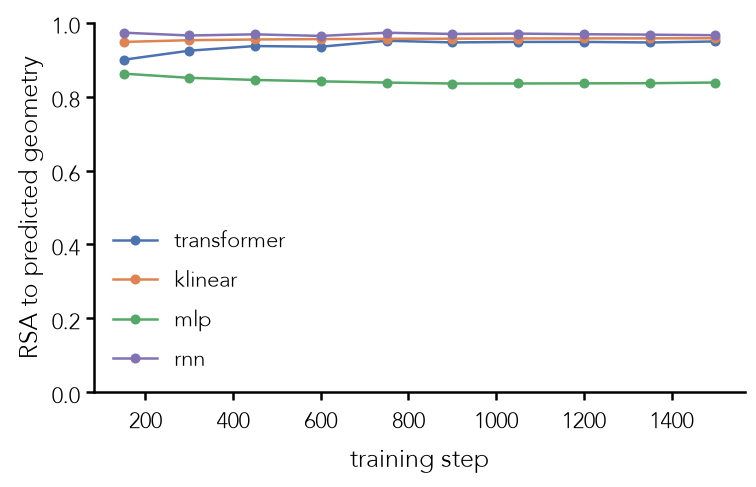

In [42]:
ARCHS = ["transformer", "klinear", "mlp", "rnn"]
results = {}
for arch in ARCHS:
    model, dataset, evaluator, history = train_inline(graph_overrides(spec) + [f"runner={arch}"])
    E_true = predicted_geometry(dataset.conditional)                       # matches the trained items
    reps = evaluator.item_representations(model)                            # pre-decode activations
    results[arch] = {"reps": reps, "model": model, "history": history,
                     "cka": cka(reps, E_true), "rsa": rsa(reps, E_true)}
    print(f"{arch:12s} CKA={results[arch]['cka']:.3f}  RSA={results[arch]['rsa']:.3f}")

plot_utils.plot_rsa_curves({a: results[a]["history"] for a in ARCHS});

## 3. Learned embeddings & representational convergence

Every architecture's token embedding (PCA to 2-D) beside the closed-form prediction — they land on
the same circle, up to a rotation/reflection CKA/RSA are invariant to. The bars quantify the match;
linear-readout heads (k-linear) print the geometry most sharply, since a nonlinear head can offload
structure into its weights instead of the embedding.

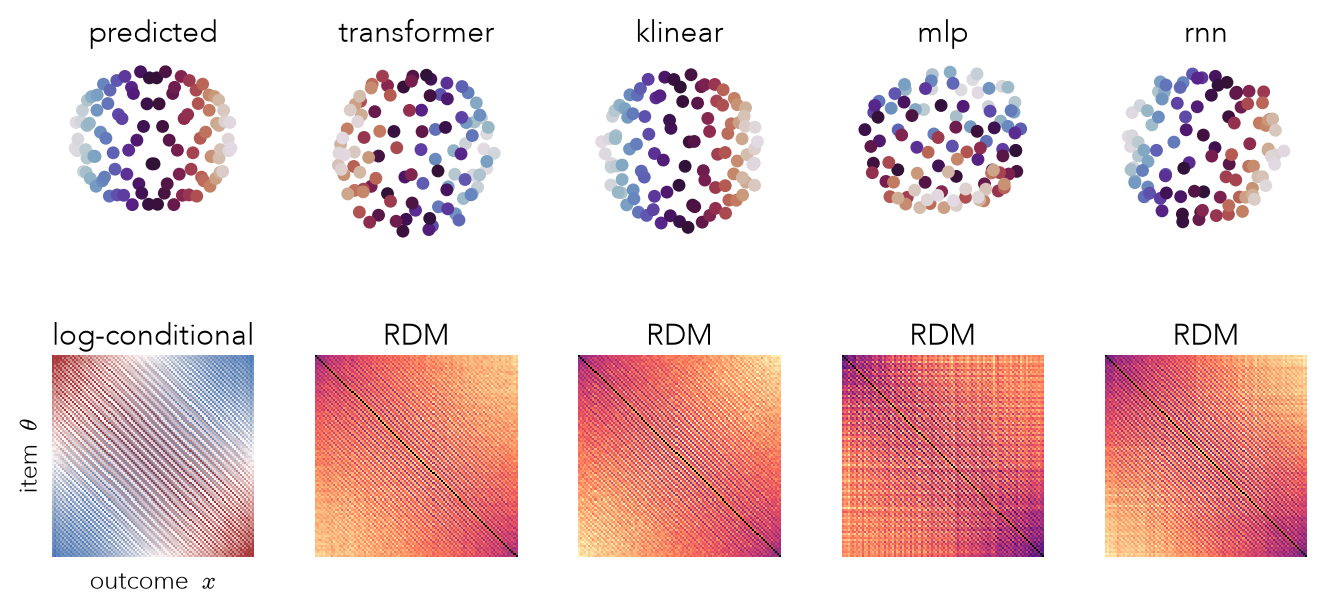

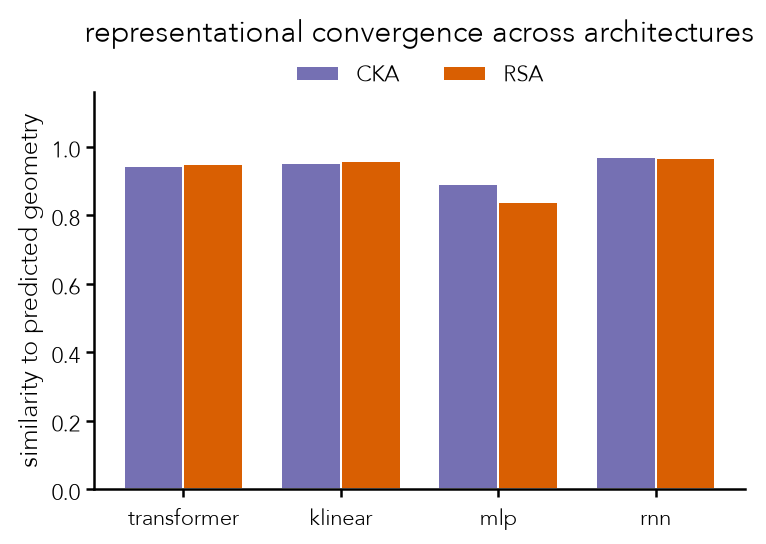

In [43]:
plot_utils.plot_embedding_panels(E_pred, {a: results[a]["reps"] for a in ARCHS}, L, spec=spec)
plot_utils.plot_convergence_bars({a: {"cka": results[a]["cka"], "rsa": results[a]["rsa"]} for a in ARCHS});

## 4. The decoder is predicted too

`factor_logcond` returns both the code `E` (compared above) **and** the decoder `D` — the readout
that maps code → output logits. Every architecture has a readout (k-linear's tensor, the MLP/RNN
final layer, the transformer's unembedding), and it should match the predicted decoder `D`: fitting
`softmax(readout · code) = p(·|x)` means `readout · codeᵀ ≈ L`, so the `(embedding, readout)` pair is
just a learned factorization of the conditional.

`D` is compared at the task's true rank (dropping the `S=0` null directions), and only up to a linear
gauge, so **CCA** is the right scalar. For the *picture*, the k-linear head is linear, so each column
of `emb · readoutᵀ` is one outcome's **decoder function** `log p(x | item)` over the item grid — a
localized bump at that outcome's location. The first figure lays the predicted decoder functions
next to the learned ones (same picture); the bar chart shows every architecture's readout recovers
the predicted decoder (CCA ≈ 1).

  readout vs predicted decoder D (CCA, rank 53):  transformer  1.000
  readout vs predicted decoder D (CCA, rank 53):  klinear      1.000
  readout vs predicted decoder D (CCA, rank 53):  mlp          1.000
  readout vs predicted decoder D (CCA, rank 53):  rnn          1.000


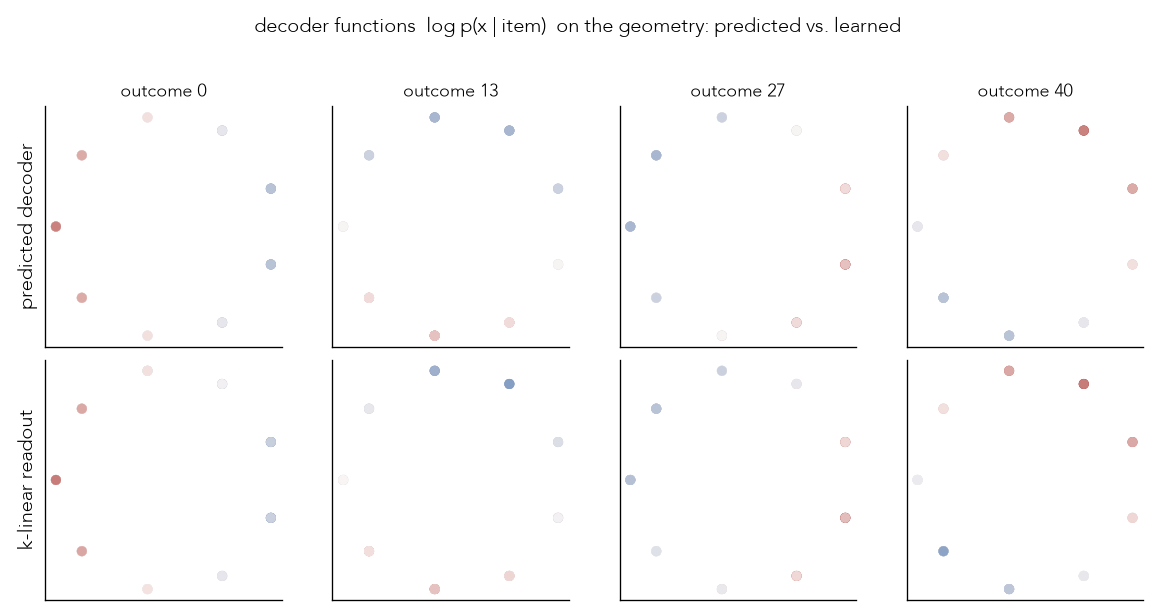

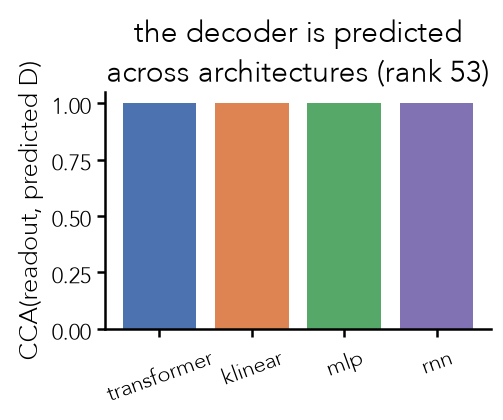

In [5]:
import matplotlib.pyplot as plt
from src.code.geometry import factor_logcond
from src.code.eval import cca

_, _, D_pred, S, _ = factor_logcond(L)          # decoder: (k, num_outcomes)
r = int((S > 1e-6).sum())                        # the conditional's true rank (~ the models' capacity)
D_geom = D_pred[:r].T                            # decoder on the meaningful subspace (num_outcomes, r)
n_out = D_geom.shape[0]                          # drop the S=0 null directions that carry no structure

def readout(model, arch):
    """Per-outcome readout (decoder) weights, restricted to the item outcomes."""
    W = (model.readout if arch == "klinear" else
         model.mlp[-1].weight if arch == "mlp" else
         model.head.weight if arch == "rnn" else
         model.get_output_embeddings().weight)   # transformer unembedding
    return W.detach().cpu().numpy()[:n_out]

# The readout equals the predicted decoder only up to a linear gauge (different from the encoder's),
# so CCA is the right metric, matched at the task's rank r.
cca_by_arch = {a: cca(readout(results[a]["model"], a), D_geom) for a in ARCHS}
for a in ARCHS:
    print(f"  readout vs predicted decoder D (CCA, rank {r}):  {a:12s} {cca_by_arch[a]:.3f}")

# k-linear has a *linear* readout, so its (embedding, readout) pair reconstructs the conditional
# exactly: softmax(emb @ readout.T) = p(.|x). Each *column* is one outcome's decoder function
# log p(x | item); shown on the predicted 2-D embedding (works for any structure). Predicted and
# learned are the same picture (both centered, since softmax ignores per-context constants).
emb = results["klinear"]["model"].get_input_embeddings().weight.detach().cpu().numpy()[:n_out]
Wk = readout(results["klinear"]["model"], "klinear")
rc = lambda A: A - A.mean(1, keepdims=True)      # softmax ignores per-row (per-context) constants
M_pred, M_lrn = rc(L), rc(emb @ Wk.T)
XY = E_pred[:, :2]
outs = [0, n_out // 4, n_out // 2, 3 * n_out // 4]
rows = [("predicted decoder", M_pred), ("k-linear readout", M_lrn)]

fig, axes = plt.subplots(2, len(outs), figsize=(2.5 * len(outs), 5.0))
for c, x in enumerate(outs):
    v = np.abs(M_pred[:, x]).max()
    for row, (label, M) in enumerate(rows):
        ax = axes[row, c]
        ax.scatter(XY[:, 0], XY[:, 1], c=M[:, x], cmap=plot_utils.FIG.diverging_cmap, vmin=-v, vmax=v, s=25)
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
        if row == 0: ax.set_title(f"outcome {x}", fontsize=11)
        if c == 0: ax.set_ylabel(label, fontsize=12)
fig.suptitle("decoder functions  log p(x | item)  on the geometry: predicted vs. learned", y=1.01)
fig.tight_layout()

# cross-architecture: every readout recovers the predicted decoder, up to its own gauge.
fig2, ax2 = plt.subplots(figsize=(4.2, 3.6))
ax2.bar(range(len(ARCHS)), [cca_by_arch[a] for a in ARCHS], color=plot_utils.FIG.categorical)
ax2.set_xticks(range(len(ARCHS))); ax2.set_xticklabels(ARCHS, rotation=20)
ax2.set_ylim(0, 1.05); ax2.set_ylabel("CCA(readout, predicted D)")
ax2.set_title(f"the decoder is predicted\nacross architectures (rank {r})")
plot_utils.FIG.style_axes(ax2)
fig2.tight_layout();